# Dubai Metro Station Profiling — DBSCAN baseline

**Author / workstream:** Aryan · **Algorithm:** DBSCAN · **Input:** 17 already-standardized station-window features from AWS Athena.

## What will we learn?

A *station-window observation* describes one Metro station during one study window. Two observations are "similar" when their **17 passenger-behaviour features** are close in 17-dimensional space.

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) finds connected groups of locally dense observations. It also marks observations that do not belong to a dense group as **noise (`-1`)**.

This notebook:
1. Loads the CSV you already exported from Athena — **no AWS credentials needed**.
2. Validates the 17-feature dataset without re-scaling it.
3. Uses a **k-distance plot** to motivate `eps`, and a documented rule to set `min_samples`/`minPts`.
4. Runs a small, reproducible parameter sensitivity search, recording the full search table.
5. Evaluates density clusters honestly: silhouette/DB index are computed **only on non-noise points** and reported beside noise coverage.
6. Saves labels, plots and metrics under `results/dbscan/` for comparison with K-means, hierarchical, spectral and ST-GRSC.

> **Methodological boundary:** This is **behavioural DBSCAN**. We use 17 standardized passenger behaviour features, **not physical latitude/longitude** or the proposed spatio-temporal graph. That graph is part of the later ST-GRSC method. Cluster labels are for **station-window profiles**, not necessarily permanent station identities.

In [3]:
import sys
print(sys.executable)

/Users/aryanchandra/.pyenv/versions/3.9.17/bin/python


## 1 · Imports and locating the file

**Why?** `pandas` loads CSV files, `numpy` handles arrays, `scikit-learn` implements DBSCAN and evaluation, and `matplotlib` creates plots. The CSV has already been downloaded with your `export_features.py` script.

This notebook works when opened from either the **repository root** or the **`notebooks/`** directory. It does not install packages or create any environments.

In [4]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors

CSV_RELATIVE = Path('results/aws_features_export.csv')
possible_roots = [Path.cwd(), Path.cwd().parent]
project_root = next((p for p in possible_roots if (p / CSV_RELATIVE).is_file()), None)
if project_root is None:
    raise FileNotFoundError(
        'Cannot find results/aws_features_export.csv. Open the notebook from the project root '
        'or notebooks/ folder, and confirm export_features.py completed.'
    )

csv_path = project_root / CSV_RELATIVE
output_dir = project_root / 'results' / 'dbscan'
output_dir.mkdir(parents=True, exist_ok=True)
print('Input:', csv_path)
print('Output directory:', output_dir)

Input: /Users/aryanchandra/Downloads/Data-Mining-MetroStations-profiling-aryan/results/aws_features_export.csv
Output directory: /Users/aryanchandra/Downloads/Data-Mining-MetroStations-profiling-aryan/results/dbscan


## 2 · Identify the 17 numerical features

The CSV also contains station names, IDs, time windows and passenger counts. **They are not input features.** We select only the 17 behavioural features so the algorithm compares **usage patterns**, not arbitrary IDs.

The table `dubai_metro.features` was already standardized upstream. In this notebook, **do not call `StandardScaler` again**: doing so could change the common feature representation and make the comparison unfair.

In [5]:
BANDS = ['00_07', '07_10', '10_16', '16_20', '20_24']
FEATURES = (
    [f'check_in_share_{band}' for band in BANDS]
    + [f'check_out_share_{band}' for band in BANDS]
    + [f'net_flow_{band}' for band in BANDS]
    + ['weekend_share', 'volume_share']
)
IDENTIFIERS = ['win', 'location_id', 'station']

df = pd.read_csv(csv_path)
missing = [c for c in IDENTIFIERS + FEATURES if c not in df.columns]
if missing:
    raise ValueError(f'Missing columns from export: {missing}')

X_df = df[FEATURES].apply(pd.to_numeric, errors='raise')
X = X_df.to_numpy(dtype=float)

if not np.isfinite(X).all():
    raise ValueError('Missing, NaN, or infinite feature values detected: inspect the export before clustering.')
if df.duplicated(['win', 'location_id']).any():
    raise ValueError('Duplicate (win, location_id) records detected: investigate before clustering.')
if len(df) < 10:
    raise ValueError('Not enough rows to conduct this DBSCAN experiment.')
if len(df) != 244:
    warnings.warn(f'Found {len(df)} records (repository example expects 244). Verify AWS export version.')

print('CSV shape:', df.shape)
print('Feature matrix shape:', X.shape)
print('Unique stations:', df['location_id'].nunique())
print('Windows:')
print(df['win'].value_counts().sort_index().to_string())
print('\nFirst five station-window IDs:')
print(df[IDENTIFIERS].head().to_string(index=False))
print('\nFeature means (standardized data; approx. 0 is typical):')
print(X_df.mean().round(3).to_string())

CSV shape: (244, 23)
Feature matrix shape: (244, 17)
Unique stations: 53
Windows:
win
W17/18    47
W18/19    45
W19/20    46
W21/22    53
W24/25    53

First five station-window IDs:
   win  location_id   station
W19/20          174 Sharaf DG
W19/20          137      ADCB
W19/20          176 Oud Metha
W19/20          172    Al Ras
W19/20          179     Creek

Feature means (standardized data; approx. 0 is typical):
check_in_share_00_07    -0.0
check_in_share_07_10     0.0
check_in_share_10_16     0.0
check_in_share_16_20    -0.0
check_in_share_20_24     0.0
check_out_share_00_07    0.0
check_out_share_07_10    0.0
check_out_share_10_16   -0.0
check_out_share_16_20    0.0
check_out_share_20_24   -0.0
net_flow_00_07          -0.0
net_flow_07_10           0.0
net_flow_10_16           0.0
net_flow_16_20           0.0
net_flow_20_24          -0.0
weekend_share            0.0
volume_share             0.0


## 3 · What do `eps` and `min_samples` mean?

- **`eps`**: radius of the neighbourhood around each profile, measured using Euclidean distance on the 17 standardized features. Too small → many points become noise. Too large → distinct groups collapse into one.
- **`min_samples` (also called `minPts`)**: number of points required in that neighbourhood **including the point itself** for it to be a *core point*. A core point can expand a DBSCAN cluster.
- **Border point:** close to a core point but not core itself. **Noise (`-1`):** not reachable from a dense cluster.

**Documented initial rule:** `min_samples = dimension + 1 = 18`. This makes density membership more conservative than a tiny default `5` in a 17-dimensional feature space. To assess sensitivity, we will also try roughly `dimension/2` and `2 × dimension`, without pretending these heuristics are theoretically optimal.

**Distance caveat:** In 17 dimensions, Euclidean distances may concentrate. The k-distance curve and noise fraction will reveal whether DBSCAN is a suitable baseline; a degenerate one-cluster/all-noise result is a legitimate experimental finding.

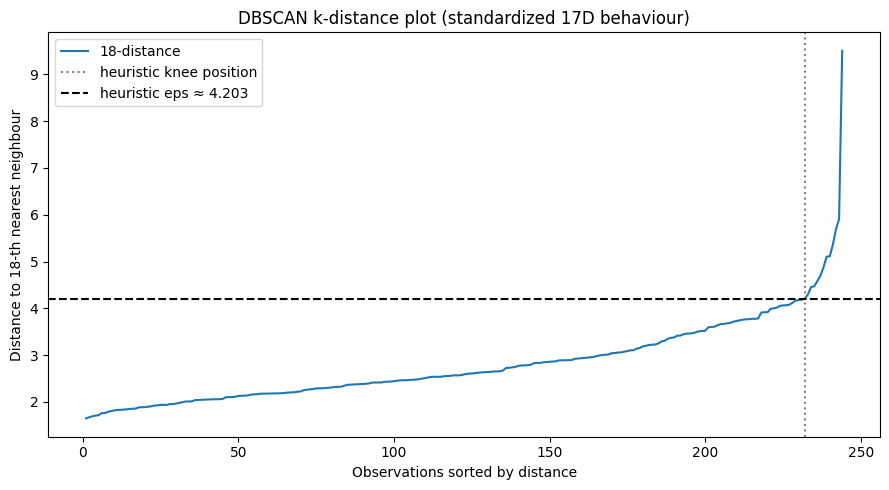

Default min_samples: 18
Candidate eps from heuristic knee: 4.2025
Inspect the curve and report whether a convincing knee is visible.


In [6]:
n_features = X.shape[1]
BASE_MIN_SAMPLES = n_features + 1             # 18 for 17 features
MIN_SAMPLES_GRID = sorted(set([max(5, n_features // 2), BASE_MIN_SAMPLES, 2 * n_features]))

# sklearn NearestNeighbors includes the query observation itself among neighbors.
# Thus the distance to the min_samples-th neighbor uses index min_samples-1.
def kth_neighbor_distances(values, min_samples):
    nn = NearestNeighbors(n_neighbors=min_samples, metric='euclidean')
    nn.fit(values)
    distances, _ = nn.kneighbors(values)
    return np.sort(distances[:, min_samples - 1])

# A transparent *heuristic* knee detector: maximum vertical gap between
# the normalized sorted curve and its endpoint-to-endpoint diagonal.
# This is not a formal guarantee that the detected eps is optimal.
def elbow_eps(sorted_distances):
    if len(sorted_distances) < 3:
        return float(sorted_distances[-1]), len(sorted_distances) - 1
    x = np.linspace(0, 1, len(sorted_distances))
    y = (sorted_distances - sorted_distances[0]) / max(
        sorted_distances[-1] - sorted_distances[0], 1e-12
    )
    deviation = x - y  # convex k-distance curve: knee lies below the diagonal
    elbow_index = int(np.argmax(deviation))
    return float(sorted_distances[elbow_index]), elbow_index

base_distances = kth_neighbor_distances(X, BASE_MIN_SAMPLES)
base_eps, elbow_idx = elbow_eps(base_distances)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(1, len(base_distances)+1), base_distances, label=f'{BASE_MIN_SAMPLES}-distance')
ax.axvline(elbow_idx + 1, linestyle=':', color='grey', label='heuristic knee position')
ax.axhline(base_eps, linestyle='--', color='black', label=f'heuristic eps ≈ {base_eps:.3f}')
ax.set(title='DBSCAN k-distance plot (standardized 17D behaviour)',
       xlabel='Observations sorted by distance',
       ylabel=f'Distance to {BASE_MIN_SAMPLES}-th nearest neighbour')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'k_distance.png', dpi=160)
plt.show()
print('Default min_samples:', BASE_MIN_SAMPLES)
print(f'Candidate eps from heuristic knee: {base_eps:.4f}')
print('Inspect the curve and report whether a convincing knee is visible.')

## 4 · Parameter sensitivity search

A single guessed radius is risky. Around the k-distance knee, test a small reproducible grid of `eps` values. We also compare `min_samples` = `dimension/2`, `dimension + 1`, and `2 × dimension`.

**How we select a candidate (predeclared rule):**
1. A *usable* run must find **at least 2 non-noise clusters**, and have **at most 40% noise**.
2. Among usable runs, maximize `non-noise silhouette × (1 − noise fraction)` (a pragmatic *coverage-adjusted* score); break ties by lower noise, then smaller `eps`.
3. If no run meets the 40% noise condition but some have ≥2 clusters, the best such run is **exploratory**, not a fully satisfactory baseline.
4. If every run produces fewer than 2 clusters, report the failure — **do not fabricate successful clusters**.

**Important evaluation caution:** Silhouette and Davies–Bouldin are computed using **non-noise points only**, so *we report coverage alongside them*. Ignoring noise would unfairly reward models that classify very few easy examples. Selection and evaluation use the same dataset, so scores are descriptive, not held-out generalization estimates.

In [7]:
def evaluate_labels(values, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    noise_frac = float((~mask).mean())
    sizes = pd.Series(labels[mask]).value_counts() if mask.any() else pd.Series(dtype=int)
    result = {
        'n_clusters': int(n_clusters),
        'noise_points': int((~mask).sum()),
        'noise_fraction': noise_frac,
        'coverage': 1 - noise_frac,
        'smallest_cluster': int(sizes.min()) if len(sizes) else 0,
        'largest_cluster': int(sizes.max()) if len(sizes) else 0,
        'silhouette_non_noise': np.nan,
        'davies_bouldin_non_noise': np.nan,
        'calinski_harabasz_non_noise': np.nan,
    }
    n_kept = int(mask.sum())
    if 2 <= n_clusters < n_kept:
        result['silhouette_non_noise'] = float(silhouette_score(values[mask], labels[mask]))
        result['davies_bouldin_non_noise'] = float(davies_bouldin_score(values[mask], labels[mask]))
        result['calinski_harabasz_non_noise'] = float(calinski_harabasz_score(values[mask], labels[mask]))
    return result

rows = []
for minpts in MIN_SAMPLES_GRID:
    distances = kth_neighbor_distances(X, minpts)
    suggested_eps, _ = elbow_eps(distances)
    # A mix of neighborhood-radius multipliers and upper quantiles gives a
    # documented, fixed-size search that is tied to the data distribution.
    candidate_eps = np.concatenate([
        suggested_eps * np.array([0.75, 0.85, 0.95, 1.00, 1.05, 1.15, 1.30]),
        np.quantile(distances, [0.65, 0.75, 0.85, 0.90, 0.95]),
    ])
    candidate_eps = sorted(set(float(v) for v in np.round(candidate_eps, 6) if v > 0))
    for eps in candidate_eps:
        model = DBSCAN(eps=eps, min_samples=minpts, metric='euclidean')
        labels = model.fit_predict(X)
        info = evaluate_labels(X, labels)
        rows.append({'min_samples': minpts, 'eps': eps, **info})

sweep = pd.DataFrame(rows)
sweep['adjusted_silhouette'] = sweep['silhouette_non_noise'] * sweep['coverage']
sweep['usable'] = (
    (sweep['n_clusters'] >= 2)
    & (sweep['noise_fraction'] <= 0.40)
    & sweep['silhouette_non_noise'].notna()
)
sweep.to_csv(output_dir / 'parameter_sweep.csv', index=False)
print('Tested configurations:', len(sweep))
print('Usable by predeclared rule:', int(sweep['usable'].sum()))
print('\nTop candidates (diagnostic, not final until selection):')
print(sweep.sort_values(['usable', 'adjusted_silhouette', 'coverage'],
                        ascending=[False, False, False], na_position='last').head(12).round(3).to_string(index=False))

Tested configurations: 36
Usable by predeclared rule: 1

Top candidates (diagnostic, not final until selection):
 min_samples   eps  n_clusters  noise_points  noise_fraction  coverage  smallest_cluster  largest_cluster  silhouette_non_noise  davies_bouldin_non_noise  calinski_harabasz_non_noise  adjusted_silhouette  usable
           8 2.593           2            32           0.131     0.869                 8              204                 0.146                     1.274                        9.193                0.127    True
          18 5.463           1             1           0.004     0.996               243              243                   NaN                       NaN                          NaN                  NaN   False
          34 5.033           1             1           0.004     0.996               243              243                   NaN                       NaN                          NaN                  NaN   False
          34 5.690           1         

## 5 · Choose and fit DBSCAN

Select from *all* candidates using the rule above. DBSCAN produces a `cluster` ID for each station-window. Remember: `-1` is **noise**, not another normal group.

In [8]:
if sweep['usable'].any():
    pool = sweep[sweep['usable']]
    selection_status = 'usable (>=2 clusters, <=40% noise)'
elif (sweep['n_clusters'] >= 2).any():
    pool = sweep[(sweep['n_clusters'] >= 2) & sweep['silhouette_non_noise'].notna()]
    selection_status = 'exploratory only: no candidate reached <=40% noise'
else:
    pool = sweep.copy()
    selection_status = 'degenerate: no multi-cluster solution found'

if 'degenerate' in selection_status:
    chosen = (pool.sort_values(['noise_fraction', 'min_samples', 'eps'],
                               ascending=[True, True, True]).iloc[0])
else:
    chosen = (pool.sort_values(['adjusted_silhouette', 'noise_fraction', 'eps'],
                               ascending=[False, True, True]).iloc[0])

chosen_eps = float(chosen['eps'])
chosen_minpts = int(chosen['min_samples'])
final_model = DBSCAN(eps=chosen_eps, min_samples=chosen_minpts, metric='euclidean')
labels = final_model.fit_predict(X)
final_metrics = evaluate_labels(X, labels)

print('Selection status:', selection_status)
print(f'Chosen eps={chosen_eps:.6f}, min_samples={chosen_minpts}')
print('Cluster count (excluding noise):', final_metrics['n_clusters'])
print(f'Noise: {final_metrics["noise_points"]}/{len(df)} ({100 * final_metrics["noise_fraction"]:.1f}%)')
print('Non-noise silhouette:', final_metrics['silhouette_non_noise'])
print('Non-noise Davies–Bouldin:', final_metrics['davies_bouldin_non_noise'])
print('Non-noise Calinski–Harabasz:', final_metrics['calinski_harabasz_non_noise'])
if final_metrics['n_clusters'] < 2:
    print('WARNING: DBSCAN did not find 2+ clusters in this grid. Do not claim successful clustering.')

Selection status: usable (>=2 clusters, <=40% noise)
Chosen eps=2.593313, min_samples=8
Cluster count (excluding noise): 2
Noise: 32/244 (13.1%)
Non-noise silhouette: 0.14620514081175698
Non-noise Davies–Bouldin: 1.273574916924123
Non-noise Calinski–Harabasz: 9.192554938700136


## 6 · Inspect clusters and station-window assignments

Cluster numbers (`0`, `1`, etc.) are **arbitrary IDs**, not predefined types such as residential/commercial. To describe a group, examine its **feature averages**, then check unscaled features if you want to report actual percentages. Standardized negative feature values are **below-average scores**, not negative passenger counts.

In [9]:
assigned = df.copy()
assigned['dbscan_cluster'] = labels
assigned['dbscan_is_noise'] = (labels == -1)

print('Assignments (first 20):')
print(assigned[['win', 'location_id', 'station', 'timed_taps', 'dbscan_cluster']].head(20).to_string(index=False))

size_table = assigned.groupby('dbscan_cluster').size().rename('station_window_count').reset_index()
print('\nCluster sizes (-1 = noise):')
print(size_table.to_string(index=False))

window_counts = pd.crosstab(assigned['win'], assigned['dbscan_cluster'])
print('\nStation-window counts by study window and cluster:')
print(window_counts.to_string())

cluster_means = assigned[assigned['dbscan_cluster'] != -1].groupby('dbscan_cluster')[FEATURES].mean()
if len(cluster_means):
    print('\nMean standardized features per cluster (rounded):')
    print(cluster_means.round(2).to_string())
else:
    print('No non-noise clusters to interpret.')

Assignments (first 20):
   win  location_id                 station  timed_taps  dbscan_cluster
W19/20          174               Sharaf DG       24085               0
W19/20          137                    ADCB       19976               0
W19/20          176               Oud Metha       14581              -1
W19/20          172                  Al Ras        6675              -1
W19/20          179                   Creek        2135              -1
W19/20          166                Abu Hail        9900               0
W19/20          171               Gold Souq        8187               0
W19/20          167   Abu Baker Al Siddique       13118               0
W19/20          162 Dubai Airport Free Zone        9985               0
W19/20          139      World Trade Centre       10723               0
W19/20          177   Dubai Healthcare City        5291               0
W19/20          132                   GGICO        6539               0
W19/20          148                  Equ

## 7 · Visualize the clusters with PCA (display only)

We cannot draw 17 dimensions on a screen. **PCA** projects profiles onto two axes so we can display them. This plot is a *visual aid*, not the space in which DBSCAN was trained: **DBSCAN uses the full original 17D features**.

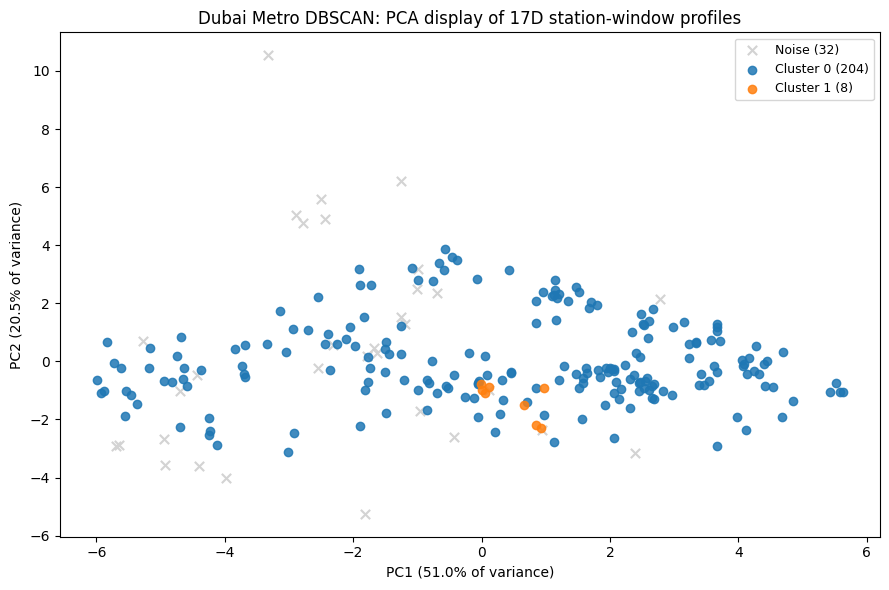

Total variance shown in PCA plane: 71.5%


In [10]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(9, 6))
for lab in sorted(set(labels)):
    mask = labels == lab
    if lab == -1:
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   label=f'Noise ({mask.sum()})', c='lightgrey', marker='x', s=45)
    else:
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   label=f'Cluster {lab} ({mask.sum()})', s=36, alpha=0.85)
ax.set(
    title='Dubai Metro DBSCAN: PCA display of 17D station-window profiles',
    xlabel=f'PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% of variance)',
    ylabel=f'PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% of variance)',
)
ax.legend(loc='best', fontsize=9)
fig.tight_layout()
fig.savefig(output_dir / 'pca_clusters.png', dpi=160)
plt.show()
print('Total variance shown in PCA plane:',
      f'{100 * pca.explained_variance_ratio_.sum():.1f}%')

## 8 · Save reproducible outputs

These files can be used when writing the report and when comparing the DBSCAN baseline with K-means, hierarchical, spectral and ST-GRSC. **The original AWS CSV is not modified.** We also write a JSON record of the selection criterion and settings.

In [11]:
assigned.to_csv(output_dir / 'dbscan_labels.csv', index=False)
size_table.to_csv(output_dir / 'cluster_sizes.csv', index=False)
window_counts.to_csv(output_dir / 'window_cluster_counts.csv')
cluster_means.to_csv(output_dir / 'cluster_feature_means_standardized.csv')

def json_number(v):
    if v is None or not np.isfinite(v):
        return None
    return float(v)

summary = {
    'method': 'DBSCAN',
    'input': str(CSV_RELATIVE),
    'n_station_window_rows': int(len(df)),
    'n_unique_stations': int(df['location_id'].nunique()),
    'n_features': int(len(FEATURES)),
    'features': FEATURES,
    'data_standardization': 'upstream in dubai_metro.features; not repeated in this notebook',
    'metric': 'euclidean',
    'initial_min_samples_rule': 'd+1',
    'initial_min_samples': BASE_MIN_SAMPLES,
    'sensitivity_min_samples': MIN_SAMPLES_GRID,
    'eps_selection': 'heuristic k-distance knee, with multiplier/quantile sensitivity grid',
    'selection_rule': 'maximize silhouette(non-noise) * coverage, among >=2 clusters and <=40% noise; fallback flagged',
    'selection_status': selection_status,
    'eps': chosen_eps,
    'min_samples': chosen_minpts,
    'n_clusters': int(final_metrics['n_clusters']),
    'noise_points': int(final_metrics['noise_points']),
    'noise_fraction': json_number(final_metrics['noise_fraction']),
    'coverage': json_number(final_metrics['coverage']),
    'silhouette_non_noise': json_number(final_metrics['silhouette_non_noise']),
    'davies_bouldin_non_noise': json_number(final_metrics['davies_bouldin_non_noise']),
    'calinski_harabasz_non_noise': json_number(final_metrics['calinski_harabasz_non_noise']),
    'scoring_note': 'scores exclude noise points; compare together with coverage and note selection uses same sample',
}
with (output_dir / 'summary.json').open('w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2)

print('Done — generated files:')
for file in sorted(output_dir.iterdir()):
    print(' -', file.relative_to(project_root))

Done — generated files:
 - results/dbscan/cluster_feature_means_standardized.csv
 - results/dbscan/cluster_sizes.csv
 - results/dbscan/dbscan_labels.csv
 - results/dbscan/k_distance.png
 - results/dbscan/parameter_sweep.csv
 - results/dbscan/pca_clusters.png
 - results/dbscan/summary.json
 - results/dbscan/window_cluster_counts.csv
